<div dir="rtl">

# کارگاه جلسه ۲۸ — خوشه‌بندی چگالی‌محور و مبتنی بر مدل

این دفترچه ابزارهایی را نشان می‌دهد که در جزوه نیامده‌اند و تمرین عملی کلاس را با پاسخ دارد. نوشتن این کدها در امتحان پرسیده نمی‌شود.

## ۱. الگوریتم OPTICS و نمودار دسترس‌پذیری

روش OPTICS نقاط را به ترتیبی مرتب می‌کند که نقاط یک خوشه کنار هم بیایند و برای هر نقطه «فاصله دسترس‌پذیری» را می‌دهد. در **نمودار دسترس‌پذیری**، هر دره یک خوشه است و عمق دره چگالی آن را نشان می‌دهد؛ مانند یک دندروگرام برای چگالی.

</div>

clusters=3  noise=235  ARI=0.956
OPTICS   -1    0   1    2
true                     
0         0  250   0    0
1       235    3  10    2
2         0    0   0  200


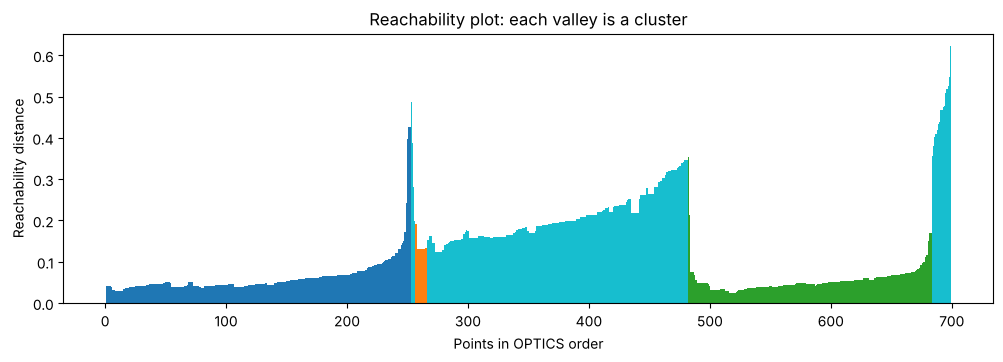

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import OPTICS
from sklearn.metrics import adjusted_rand_score

X, y = make_blobs(n_samples=[250, 250, 200], centers=[[0, 0], [6, 4], [9, -1]],
                  cluster_std=[0.5, 2.0, 0.4], random_state=42)
Xs = StandardScaler().fit_transform(X)
opt = OPTICS(min_samples=10, xi=0.1).fit(Xs)
print(f"clusters={len(set(opt.labels_) - {-1})}  noise={np.sum(opt.labels_ == -1)}  ARI={adjusted_rand_score(y, opt.labels_):.3f}")
print(pd.crosstab(y, opt.labels_, rownames=["true"], colnames=["OPTICS"]))

reach = opt.reachability_[opt.ordering_]
reach[np.isinf(reach)] = np.nan                      # the first point has no reachability
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(range(len(reach)), reach, color=plt.cm.tab10(opt.labels_[opt.ordering_] % 10), width=1.0)
ax.set(xlabel="Points in OPTICS order", ylabel="Reachability distance", title="Reachability plot: each valley is a cluster")
plt.show()

<div dir="rtl">

دو دره عمیق و باریک دو توده متراکم‌اند؛ توده پراکنده دره‌ای کم‌عمق و پهن می‌سازد که بیشتر نقاطش بالای آستانه xi می‌مانند و نویز اعلام می‌شوند. روش‌های چگالی‌محور توده پراکنده را «کم‌تراکم» می‌بینند، نه خوشه.

## ۲. احتمال عضویت در HDBSCAN

ویژگی `probabilities_` در HDBSCAN نشان می‌دهد هر نقطه چقدر محکم به خوشه‌اش تعلق دارد (صفر برای نویز). نقاط حاشیه خوشه پراکنده احتمال کمتری دارند.

</div>

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN

X, y = make_blobs(n_samples=[250, 250, 200], centers=[[0, 0], [6, 4], [9, -1]],
                  cluster_std=[0.5, 2.0, 0.4], random_state=42)
hd = HDBSCAN(min_cluster_size=15, copy=True).fit(StandardScaler().fit_transform(X))
df = pd.DataFrame({"true_group": y, "label": hd.labels_, "prob": hd.probabilities_})
print(df.groupby("true_group").agg(noise=("label", lambda s: (s == -1).sum()), mean_prob=("prob", "mean")).round(2))

            noise  mean_prob
true_group                  
0               0       0.74
1              63       0.59
2               0       0.65


<div dir="rtl">

## ۳. تشخیص ناهنجاری با چگالی GMM

متد `score_samples` لگاریتم چگالی هر نقطه را زیر مدل برازش‌شده می‌دهد. نقاطی با کمترین چگالی (مثلاً ۲ درصد پایین) را می‌توان ناهنجار دانست ← جلسه ۱۱.

</div>

In [3]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"
mall = pd.read_csv(url)
cols = ["Annual Income (k$)", "Spending Score (1-100)"]
Xs = StandardScaler().fit_transform(mall[cols])
gm = GaussianMixture(5, n_init=5, random_state=42).fit(Xs)
mall["log_density"] = gm.score_samples(Xs)
threshold = np.percentile(mall["log_density"], 2)
print(mall[mall["log_density"] < threshold][cols + ["log_density"]].round(2).to_string(index=False))

 Annual Income (k$)  Spending Score (1-100)  log_density
                 99                      39        -5.22
                126                      74        -5.24
                137                      18        -6.73
                137                      83        -6.79


<div dir="rtl">

## تمرین عملی کلاس (۳۰ دقیقه): مقایسه k-Means، DBSCAN و GMM

دو داده شبیه‌سازی‌شده بسازید: `make_moons(n_samples=500, noise=0.07, random_state=42)` و `make_blobs(n_samples=500, centers=3, cluster_std=[1.0, 2.5, 0.5], random_state=42)`. هر دو را استاندارد کنید.

1. برای داده هلالی نمودار k-distance (k برابر ۵) را رسم و eps مناسب را انتخاب کنید.
2. روی هر داده الگوریتم k-Means و GMM (با تعداد واقعی خوشه)، DBSCAN (با eps منتخب) و HDBSCAN را اجرا کنید.
3. برای هر ترکیب، تعداد خوشه، تعداد نویز و شاخص ARI را در یک جدول و نتیجه‌ها را در یک شبکه ۲ در ۴ نمودار رسم کنید.
4. کدام الگوریتم روی کدام داده بهتر است و چرا؟ آیا یک eps برای هر دو داده کار می‌کند؟
5. برای داده توده‌ای، تعداد مؤلفه GMM را با BIC (۱ تا ۶) انتخاب کنید.

</div>

In [4]:
# Write your solution here

<div dir="rtl">

### پاسخ تمرین

</div>

moons k-distance percentiles 90/95/99=[0.152, 0.179, 0.246]


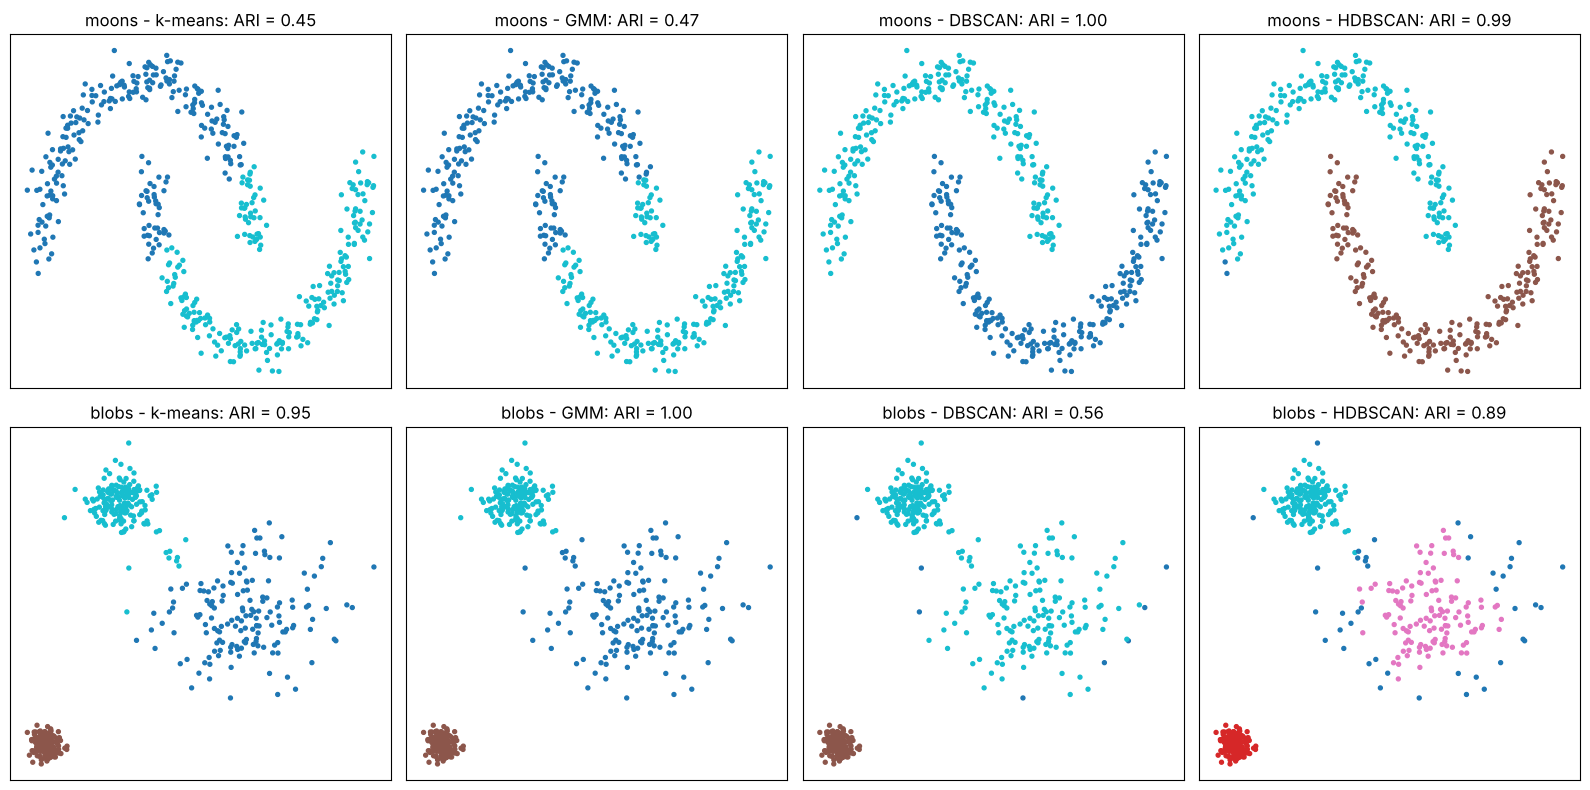

           ARI        clusters       noise      
data     blobs  moons    blobs moons blobs moons
model                                           
DBSCAN   0.564  1.000      2.0   2.0   8.0   0.0
GMM      1.000  0.467      3.0   2.0   0.0   0.0
HDBSCAN  0.892  0.992      3.0   2.0  42.0   2.0
k-means  0.947  0.445      3.0   2.0   0.0   0.0


BIC={1: 2786, 2: 1107, 3: 635, 4: 671, 5: 694, 6: 715}  best=3


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

Xm, ym = make_moons(n_samples=500, noise=0.07, random_state=42)
Xb, yb = make_blobs(n_samples=500, centers=3, cluster_std=[1.0, 2.5, 0.5], random_state=42)
data = {"moons": (StandardScaler().fit_transform(Xm), ym, 2), "blobs": (StandardScaler().fit_transform(Xb), yb, 3)}

# 1. k-distance for the moons
dist, _ = NearestNeighbors(n_neighbors=5).fit(data["moons"][0]).kneighbors(data["moons"][0])
print(f"moons k-distance percentiles 90/95/99={np.percentile(dist[:, -1], [90, 95, 99]).round(3).tolist()}")

# 2-3. Four algorithms on both data sets
rows = []
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, (name, (X, y, k)) in enumerate(data.items()):
    models = {"k-means": KMeans(k, n_init=10, random_state=42), "GMM": GaussianMixture(k, n_init=5, random_state=42),
              "DBSCAN": DBSCAN(eps=0.3, min_samples=5), "HDBSCAN": HDBSCAN(min_cluster_size=15, copy=True)}
    for j, (mname, model) in enumerate(models.items()):
        lab = model.fit_predict(X)
        ari = adjusted_rand_score(y, lab)
        rows.append({"data": name, "model": mname, "clusters": len(set(lab) - {-1}),
                     "noise": int(np.sum(lab == -1)), "ARI": round(ari, 3)})
        axes[i, j].scatter(X[:, 0], X[:, 1], c=lab, cmap="tab10", s=8)
        axes[i, j].set(title=f"{name} - {mname}: ARI = {ari:.2f}", xticks=[], yticks=[])
plt.tight_layout()
plt.show()
print(pd.DataFrame(rows).pivot(index="model", columns="data", values=["ARI", "clusters", "noise"]))

# 5. BIC for the blobs
Xs = data["blobs"][0]
bic = {k: GaussianMixture(k, n_init=3, random_state=42).fit(Xs).bic(Xs) for k in range(1, 7)}
print(f"BIC={ {k: round(v) for k, v in bic.items()} }  best={min(bic, key=bic.get)}")

<div dir="rtl">

### پاسخ‌های کلیدی

- **نمودار k-distance هلال‌ها:** صدک ۹۹ فاصله تا پنجمین همسایه حدود ۰.۲۵ است؛ eps برابر ۰.۳ کمی بالای زانو انتخاب شد.

| الگوریتم | ARI هلال‌ها | ARI توده‌ها | نویز توده‌ها |
|:---:|:---:|:---:|:---:|
| الگوریتم k-Means | 0.445 | 0.947 | 0 |
| مدل GMM | 0.467 | 1.000 | 0 |
| روش DBSCAN (شعاع 0.3) | 1.000 | 0.564 | 8 |
| روش HDBSCAN | 0.992 | 0.892 | 42 |

- **هلال‌ها:** روش‌های چگالی‌محور برنده‌اند؛ k-Means و GMM که خوشه‌های محدب یا بیضوی فرض می‌کنند هر هلال را از وسط نصف می‌کنند.
- **توده‌ها:** مدل GMM بی‌خطاست چون داده دقیقاً آمیخته‌ای از سه گاوسی با پراکندگی متفاوت است. روش DBSCAN با همان eps برابر ۰.۳ فقط **دو** خوشه یافت: دو توده نزدیک از طریق توده پراکنده به هم وصل شدند. یک eps برای هر دو داده کار نمی‌کند.
- روش HDBSCAN روی هر دو داده بدون تنظیم شعاع نتیجه خوبی داد، به قیمت ۴۲ نقطه نویز در حاشیه توده پراکنده.
- **معیار BIC** برای توده‌ها کمینه را در **سه** مؤلفه دارد (۶۳۵ در برابر ۶۷۱ برای چهار مؤلفه).

</div>